# Лабораторная работа 2: генерация карты по спутниковому снимку (pix2pix)

**Задача.** На вход подаётся снимок со спутника (.png / .bmp / .jpg), на выходе получается схематическая карта той же местности: дороги, парки, вода и здания нарисованы так, как это принято на картах.

**Подход.** Нейросеть pix2pix ([Isola et al., 2016](https://arxiv.org/abs/1611.07004)) на PyTorch:
- **генератор U-Net** превращает снимок в карту; прямые связи между кодировщиком и декодером передают мелкие детали (контуры дорог и кварталов) напрямую на выход;
- **дискриминатор PatchGAN** смотрит на пары «снимок + карта» кусками 70×70 и решает, настоящая карта в каждом куске или нарисованная генератором;
- ошибка генератора = ошибка «обмана» дискриминатора + 100 × попиксельная разница с настоящей картой (L1).

Для сравнения тот же U-Net обучается **только на L1**, без дискриминатора. Это показывает, что даёт дискриминатор.

**Данные.** Датасет `maps` от авторов pix2pix: 1096 пар для обучения и 1098 для проверки. Каждая пара — снимок Google Maps и карта того же места.

**Оценка.** L1, PSNR, SSIM и LPIPS на проверочных парах.

## 1. Подготовка

In [1]:
import os
import random
import tarfile
import time
import warnings
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Скрытие служебных предупреждений библиотек
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Вычисления на видеокарте
DEVICE = torch.device("cuda")

# Одинаковые случайные числа при каждом запуске
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Папка для распакованного датасета
DATA_DIR = Path("data")
# Папка для весов моделей
CKPT_DIR = Path("checkpoints")
# Папка для карт, нарисованных по своим снимкам
RESULTS_DIR = Path("results")
for folder in (DATA_DIR, CKPT_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Размер картинки на входе и выходе сети
IMG_SIZE = 256
# Размер, к которому приводится картинка перед вырезанием случайного куска IMG_SIZE
LOAD_SIZE = 286

## 2. Данные

In [2]:
# Распаковка maps из архива
MAPS_DIR = DATA_DIR / "maps"
if not MAPS_DIR.exists():
    with tarfile.open(Path("..", "..", "maps.tar.gz")) as archive:
        if hasattr(tarfile, "data_filter"):
            archive.extractall(DATA_DIR, filter="data")
        else:
            archive.extractall(DATA_DIR)

# В каждом файле слева снимок, справа карта
train_files = sorted((MAPS_DIR / "train").glob("*.jpg"))
valid_files = sorted((MAPS_DIR / "val").glob("*.jpg"))

print("Обучающих пар:", len(train_files))
print("Проверочных пар:", len(valid_files))

Обучающих пар: 1096
Проверочных пар: 1098


Загрузка обучающих пар:   0%|          | 0/1096 [00:00<?, ?it/s]

Загрузка проверочных пар:   0%|          | 0/1098 [00:00<?, ?it/s]

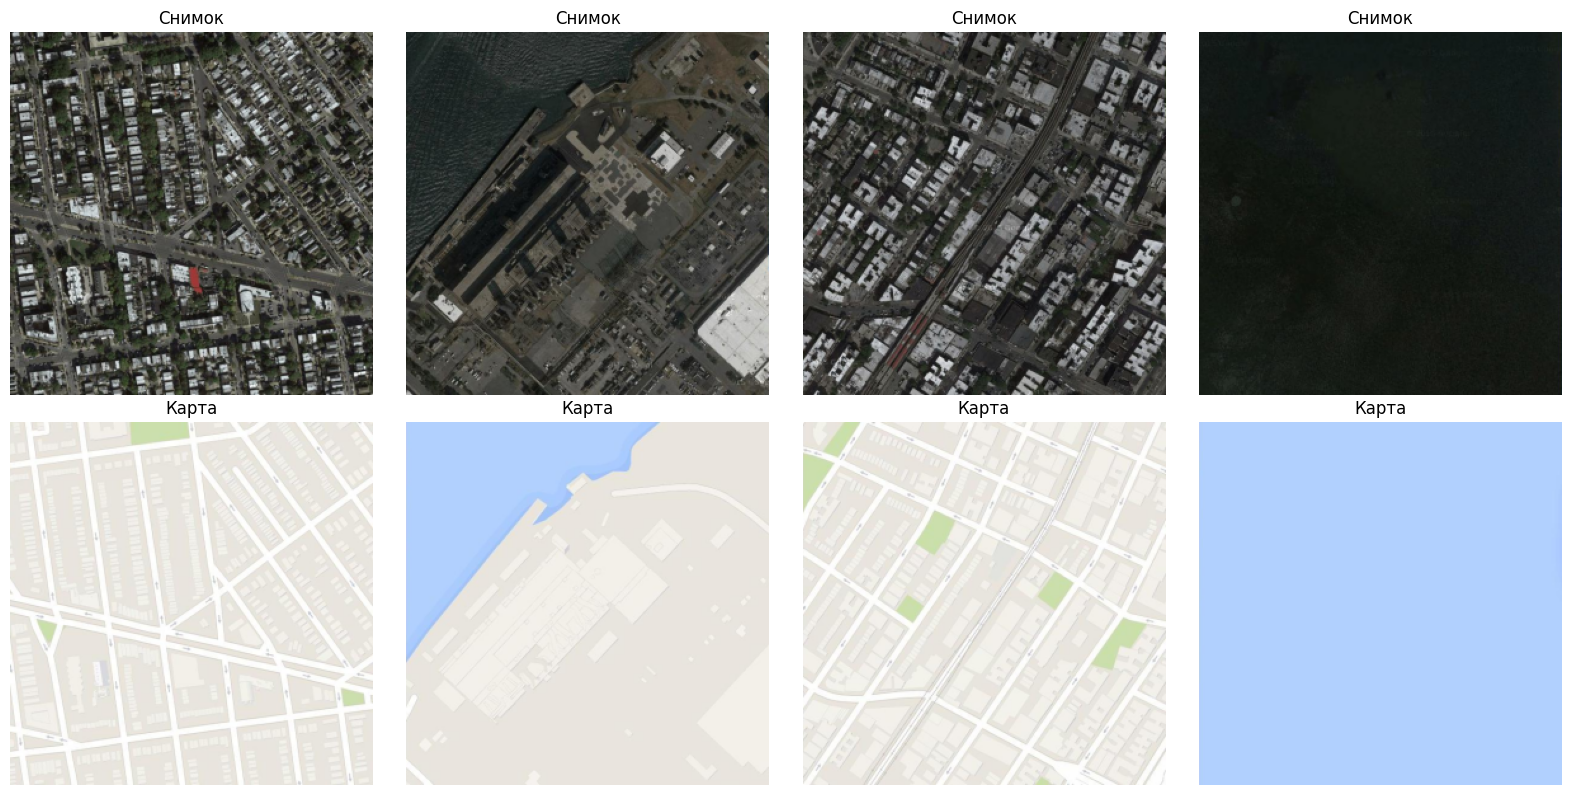

In [3]:
def read_rgb(path):
    # Читает картинку в RGB
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Не удалось прочитать {path}: нужен файл .png, .bmp или .jpg")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def save_rgb(path, img):
    # Сохраняет картинку RGB
    if not cv2.imwrite(str(path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR)):
        raise ValueError(f"Не удалось сохранить {path}")


def load_pair(path):
    # Читает файл с парой и делит его пополам: левая половина — снимок, правая — карта (обе в RGB)
    img = read_rgb(path)
    half = img.shape[1] // 2
    return img[:, :half], img[:, half:]


def resize(img, size):
    # Приводит картинку к квадрату size×size
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def to_tensor(img):
    # Переводит картинку 0..255 в тензор -1..1 формы (каналы, высота, ширина); выход генератора тоже -1..1
    return torch.from_numpy(img.transpose(2, 0, 1).copy()).float() / 127.5 - 1.0


def to_images(tensor):
    # Переводит пачку тензоров -1..1 обратно в список картинок 0..255
    imgs = ((tensor.clamp(-1, 1) + 1) * 127.5).round().byte()
    return list(imgs.permute(0, 2, 3, 1).cpu().numpy())


class MapsDataset(Dataset):
    # Пары «снимок → карта» для обучения: случайный кусок и случайное отражение, одинаковые для снимка и карты

    def __init__(self, pairs):
        # pairs — список пар (снимок, карта) размера LOAD_SIZE×LOAD_SIZE
        self.pairs = pairs

    def __len__(self):
        # Количество пар за одну эпоху
        return len(self.pairs)

    def __getitem__(self, idx):
        # Вырезает одинаковый случайный кусок IMG_SIZE×IMG_SIZE из снимка и карты, иногда отражает по горизонтали
        sat, mp = self.pairs[idx]
        y = random.randint(0, LOAD_SIZE - IMG_SIZE)
        x = random.randint(0, LOAD_SIZE - IMG_SIZE)
        sat = sat[y:y + IMG_SIZE, x:x + IMG_SIZE]
        mp = mp[y:y + IMG_SIZE, x:x + IMG_SIZE]
        if random.random() < 0.5:
            sat, mp = sat[:, ::-1], mp[:, ::-1]
        return to_tensor(sat), to_tensor(mp)


# Обучающие пары в памяти, уменьшенные до LOAD_SIZE
train_pairs = []
for p in tqdm(train_files, desc="Загрузка обучающих пар"):
    sat, mp = load_pair(p)
    train_pairs.append((resize(sat, LOAD_SIZE), resize(mp, LOAD_SIZE)))

# Проверочные пары в памяти, сразу размера IMG_SIZE
valid_sat, valid_map = [], []
for p in tqdm(valid_files, desc="Загрузка проверочных пар"):
    sat, mp = load_pair(p)
    valid_sat.append(resize(sat, IMG_SIZE))
    valid_map.append(resize(mp, IMG_SIZE))

# Количество пар в одной порции обучения
BATCH_SIZE = 4

# Порции готовятся в основном процессе (num_workers=0)
train_loader = DataLoader(
    MapsDataset(train_pairs),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True,
)

# Несколько обучающих пар для наглядности
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col in range(4):
    sat, mp = train_pairs[col * 200]
    axes[0, col].imshow(sat)
    axes[0, col].set_title("Снимок")
    axes[1, col].imshow(mp)
    axes[1, col].set_title("Карта")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Модели

In [4]:
def down_block(in_ch, out_ch, norm=True):
    # Блок кодировщика: свёртка с шагом 2 уменьшает картинку вдвое, затем нормализация и активация
    layers = [nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=not norm)]
    if norm:
        layers.append(nn.BatchNorm2d(out_ch))
    layers.append(nn.LeakyReLU(0.2))
    return nn.Sequential(*layers)


def up_block(in_ch, out_ch, dropout=False):
    # Блок декодера: обратная свёртка увеличивает картинку вдвое; dropout добавляет случайность, как в статье
    layers = [nn.ConvTranspose2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False), nn.BatchNorm2d(out_ch)]
    if dropout:
        layers.append(nn.Dropout(0.5))
    layers.append(nn.ReLU())
    return nn.Sequential(*layers)


class UNetGenerator(nn.Module):
    # Генератор U-Net: 8 раз уменьшает снимок до 1×1, затем 8 раз увеличивает обратно до карты;
    # на каждом шаге увеличения к признакам добавляются признаки того же размера из кодировщика

    def __init__(self):
        super().__init__()
        # Кодировщик: 256 → 128 → 64 → 32 → 16 → 8 → 4 → 2 → 1
        self.downs = nn.ModuleList([
            down_block(3, 64, norm=False),
            down_block(64, 128),
            down_block(128, 256),
            down_block(256, 512),
            down_block(512, 512),
            down_block(512, 512),
            down_block(512, 512),
            down_block(512, 512, norm=False),
        ])
        # Декодер: 1 → 2 → 4 → ... → 128; число входных каналов удвоено из-за добавленных признаков кодировщика
        self.ups = nn.ModuleList([
            up_block(512, 512, dropout=True),
            up_block(1024, 512, dropout=True),
            up_block(1024, 512, dropout=True),
            up_block(1024, 512),
            up_block(1024, 256),
            up_block(512, 128),
            up_block(256, 64),
        ])
        # Последнее увеличение до 256 и сборка цветной картинки со значениями -1..1
        self.final = nn.Sequential(nn.ConvTranspose2d(128, 3, 4, stride=2, padding=1), nn.Tanh())

    def forward(self, x):
        # Снимок -> признаки всех размеров -> карта
        skips = []
        for block in self.downs:
            x = block(x)
            skips.append(x)
        # Признаки кодировщика от маленьких к большим, без самого маленького (с него начинается декодер)
        skips = skips[-2::-1]
        for block, skip in zip(self.ups, skips):
            x = torch.cat([block(x), skip], dim=1)
        return self.final(x)


class PatchDiscriminator(nn.Module):
    # Дискриминатор PatchGAN: для пары «снимок + карта» выдаёт сетку 30×30 оценок,
    # каждая оценивает свой кусок 70×70: настоящая карта в нём или нарисованная

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(6, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 512, 4, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2),
            nn.Conv2d(512, 1, 4, stride=1, padding=1),
        )

    def forward(self, sat, mp):
        # Снимок и карта склеиваются по каналам: дискриминатор оценивает, подходит ли карта к этому снимку
        return self.body(torch.cat([sat, mp], dim=1))


def init_weights(module):
    # Начальные веса из нормального распределения с разбросом 0.02, как в статье
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

## 4. Инструменты оценки качества

In [5]:
import lpips
from skimage.metrics import structural_similarity


@torch.no_grad()
def translate(model, sat_imgs, batch=16):
    # Превращает список снимков в список карт; режим модели после вызова остаётся прежним
    was_training = model.training
    model.eval()
    result = []
    for i in range(0, len(sat_imgs), batch):
        x = torch.stack([to_tensor(s) for s in sat_imgs[i:i + batch]]).to(DEVICE)
        result.extend(to_images(model(x)))
    model.train(was_training)
    return result


def l1_error(pred, real):
    # Средняя разница яркости пикселей (0..255): чем меньше, тем ближе к настоящей карте
    return np.mean(np.abs(pred.astype(np.float64) - real.astype(np.float64)))


def psnr(pred, real):
    # PSNR в децибелах по всем трём цветам: чем больше, тем ближе к настоящей карте
    mse = np.mean((pred.astype(np.float64) - real.astype(np.float64)) ** 2)
    return 10 * np.log10(255.0 ** 2 / max(mse, 1e-10))


def ssim(pred, real):
    # SSIM от 0 до 1: насколько совпадают структура и контраст карт
    return structural_similarity(pred, real, channel_axis=2, data_range=255)


# Сеть для метрики LPIPS
lpips_model = lpips.LPIPS(net="alex", verbose=False).to(DEVICE)


@torch.no_grad()
def lpips_score(pred, real):
    # LPIPS: насколько непохожими картинки кажутся человеку; чем меньше, тем лучше
    a = to_tensor(pred).unsqueeze(0).to(DEVICE)
    b = to_tensor(real).unsqueeze(0).to(DEVICE)
    return lpips_model(a, b).item()


# Количество проверочных пар для быстрой оценки во время обучения
QUICK_VALID = 100


def quick_l1(model):
    # Средняя ошибка L1 на первых QUICK_VALID проверочных парах
    preds = translate(model, valid_sat[:QUICK_VALID])
    return np.mean([l1_error(p, r) for p, r in zip(preds, valid_map[:QUICK_VALID])])

## 5. Функция обучения

Одна функция обучает обе модели. Если дискриминатор не передан, генератор учится только на L1.

In [6]:
# Подбор самых быстрых способов вычисления свёрток под размер картинок
torch.backends.cudnn.benchmark = True

# Количество эпох обучения каждой модели; первая половина — с постоянной скоростью обучения, вторая — с плавным снижением до нуля
EPOCHS = 100
# Скорость обучения из статьи
LR = 2e-4
# Вес попиксельной ошибки L1 из статьи
L1_WEIGHT = 100.0

bce_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()


def lr_factor(epoch):
    # Множитель скорости обучения: 1 в первой половине эпох, затем линейно падает почти до нуля
    decay_start = EPOCHS // 2
    return 1.0 - max(0, epoch - decay_start + 1) / (EPOCHS - decay_start + 1)


def save_state(path, state):
    # Сохраняет состояние обучения через временный файл, прерванная запись не портит прошлое сохранение
    tmp_path = path.with_name(path.name + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


def train_model(generator, discriminator, ckpt_name):
    # Обучает генератор (и дискриминатор, если он передан).
    # После каждой эпохи всё состояние обучения (веса, оптимизаторы, номер эпохи, история)
    # сохраняется в CKPT_DIR / "<ckpt_name>_state.pth".
    # Если такой файл уже есть, обучение продолжается со следующей эпохи;
    # если все эпохи уже пройдены, модели просто загружаются из файла без обучения.
    # Возвращает историю: ошибки L1, «обмана», дискриминатора и L1 на проверке после каждой эпохи
    use_gan = discriminator is not None
    opt_g = torch.optim.Adam(generator.parameters(), lr=LR, betas=(0.5, 0.999))
    sched_g = torch.optim.lr_scheduler.LambdaLR(opt_g, lr_factor)
    if use_gan:
        opt_d = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=(0.5, 0.999))
        sched_d = torch.optim.lr_scheduler.LambdaLR(opt_d, lr_factor)
        discriminator.train()
    generator.train()

    state_path = CKPT_DIR / f"{ckpt_name}_state.pth"
    history = []
    start_epoch = 1

    # Продолжение с места остановки, если есть сохранение
    if state_path.exists():
        state = torch.load(state_path, map_location="cpu")
        generator.load_state_dict(state["generator"])
        opt_g.load_state_dict(state["opt_g"])
        sched_g.load_state_dict(state["sched_g"])
        if use_gan:
            discriminator.load_state_dict(state["discriminator"])
            opt_d.load_state_dict(state["opt_d"])
            sched_d.load_state_dict(state["sched_d"])
        history = state["history"]
        start_epoch = state["epoch"] + 1
        print(f"Найдено сохранение {state_path.name}: пройдено эпох {state['epoch']} из {EPOCHS}")
        del state

    for epoch in range(start_epoch, EPOCHS + 1):
        start = time.time()
        sum_l1, sum_gan, sum_d = 0.0, 0.0, 0.0

        for sat, real_map in tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS}", leave=False):
            sat = sat.to(DEVICE, non_blocking=True)
            real_map = real_map.to(DEVICE, non_blocking=True)
            fake_map = generator(sat)

            if use_gan:
                # Обучение дискриминатора: настоящие пары -> 1, пары с нарисованной картой -> 0
                real_out = discriminator(sat, real_map)
                fake_out = discriminator(sat, fake_map.detach())
                d_loss = 0.5 * (bce_loss(real_out, torch.ones_like(real_out))
                                + bce_loss(fake_out, torch.zeros_like(fake_out)))
                opt_d.zero_grad()
                d_loss.backward()
                opt_d.step()

                # Ошибка «обмана»: генератор хочет, чтобы дискриминатор принял его карту за настоящую
                fake_out = discriminator(sat, fake_map)
                gan_loss = bce_loss(fake_out, torch.ones_like(fake_out))
                sum_gan += gan_loss.item()
                sum_d += d_loss.item()
            else:
                gan_loss = 0.0

            # Обучение генератора: «обман» дискриминатора плюс близость к настоящей карте
            pix_loss = l1_loss(fake_map, real_map)
            g_loss = gan_loss + L1_WEIGHT * pix_loss
            opt_g.zero_grad()
            g_loss.backward()
            opt_g.step()
            sum_l1 += pix_loss.item()

        sched_g.step()
        if use_gan:
            sched_d.step()

        n = len(train_loader)
        val_l1 = float(quick_l1(generator))
        history.append({"l1": sum_l1 / n, "gan": sum_gan / n, "d": sum_d / n, "val_l1": val_l1})

        # Сохранение всего состояния обучения после каждой эпохи
        state = {
            "epoch": epoch,
            "history": history,
            "generator": generator.state_dict(),
            "opt_g": opt_g.state_dict(),
            "sched_g": sched_g.state_dict(),
        }
        if use_gan:
            state["discriminator"] = discriminator.state_dict()
            state["opt_d"] = opt_d.state_dict()
            state["sched_d"] = sched_d.state_dict()
        save_state(state_path, state)
        del state

        text = f"Эпоха {epoch:3d}: L1 {sum_l1 / n:.4f}"
        if use_gan:
            text += f", обман {sum_gan / n:.3f}, дискриминатор {sum_d / n:.3f}"
        print(text + f", L1 на проверке {val_l1:.2f}, {time.time() - start:.0f} с")
    return history

## 6. Обучение U-Net только на L1 (для сравнения)

In [7]:
random.seed(42)
torch.manual_seed(42)

generator_l1 = UNetGenerator().to(DEVICE)
generator_l1.apply(init_weights)
history_l1 = train_model(generator_l1, None, "unet_l1")

Эпоха 1/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха   1: L1 0.1415, L1 на проверке 13.49, 178 с


Эпоха 2/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха   2: L1 0.0976, L1 на проверке 13.17, 81 с


Эпоха 3/100:   0%|          | 0/274 [00:00<?, ?it/s]

...

Эпоха  98: L1 0.0439, L1 на проверке 6.84, 79 с


Эпоха 99/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха  99: L1 0.0438, L1 на проверке 6.80, 72 с


Эпоха 100/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха 100: L1 0.0436, L1 на проверке 6.80, 73 с


## 7. Обучение pix2pix (L1 + дискриминатор)

In [8]:
random.seed(42)
torch.manual_seed(42)

generator = UNetGenerator().to(DEVICE)
discriminator = PatchDiscriminator().to(DEVICE)
generator.apply(init_weights)
discriminator.apply(init_weights)
history_gan = train_model(generator, discriminator, "pix2pix")

Эпоха 1/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха   1: L1 0.1513, обман 1.802, дискриминатор 0.461, L1 на проверке 17.47, 135 с


Эпоха 2/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха   2: L1 0.1099, обман 1.645, дискриминатор 0.412, L1 на проверке 12.46, 132 с


Эпоха 3/100:   0%|          | 0/274 [00:00<?, ?it/s]

...

Эпоха  98: L1 0.0655, обман 4.208, дискриминатор 0.044, L1 на проверке 8.43, 135 с


Эпоха 99/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха  99: L1 0.0657, обман 4.215, дискриминатор 0.043, L1 на проверке 8.46, 140 с


Эпоха 100/100:   0%|          | 0/274 [00:00<?, ?it/s]

Эпоха 100: L1 0.0653, обман 4.116, дискриминатор 0.043, L1 на проверке 8.62, 133 с


## 8. Оценка на проверочных парах

In [9]:
# Сравниваемые модели
models = {
    "U-Net (только L1)": generator_l1,
    "pix2pix": generator,
}

# Карты, нарисованные каждой моделью для всех проверочных снимков
predictions = {name: translate(model, valid_sat) for name, model in models.items()}

results = {name: {"L1": [], "PSNR": [], "SSIM": [], "LPIPS": []} for name in models}
for i in tqdm(range(len(valid_sat)), desc="Оценка"):
    for name in models:
        pred, real = predictions[name][i], valid_map[i]
        results[name]["L1"].append(l1_error(pred, real))
        results[name]["PSNR"].append(psnr(pred, real))
        results[name]["SSIM"].append(ssim(pred, real))
        results[name]["LPIPS"].append(lpips_score(pred, real))

# Итоговая таблица: ↑ — чем больше, тем лучше, ↓ — чем меньше, тем лучше
print(f"{'Модель':<20}{'L1 ↓':>8}{'PSNR, дБ ↑':>12}{'SSIM ↑':>10}{'LPIPS ↓':>10}")
for name, m in results.items():
    print(f"{name:<20}{np.mean(m['L1']):>8.2f}{np.mean(m['PSNR']):>12.2f}"
          f"{np.mean(m['SSIM']):>10.4f}{np.mean(m['LPIPS']):>10.4f}")

Оценка:   0%|          | 0/1098 [00:00<?, ?it/s]

Модель                  L1 ↓  PSNR, дБ ↑    SSIM ↑   LPIPS ↓
U-Net (только L1)       6.79       27.28    0.7491    0.2556
pix2pix                 8.76       25.59    0.6301    0.1991


## 9. Визуальное сравнение

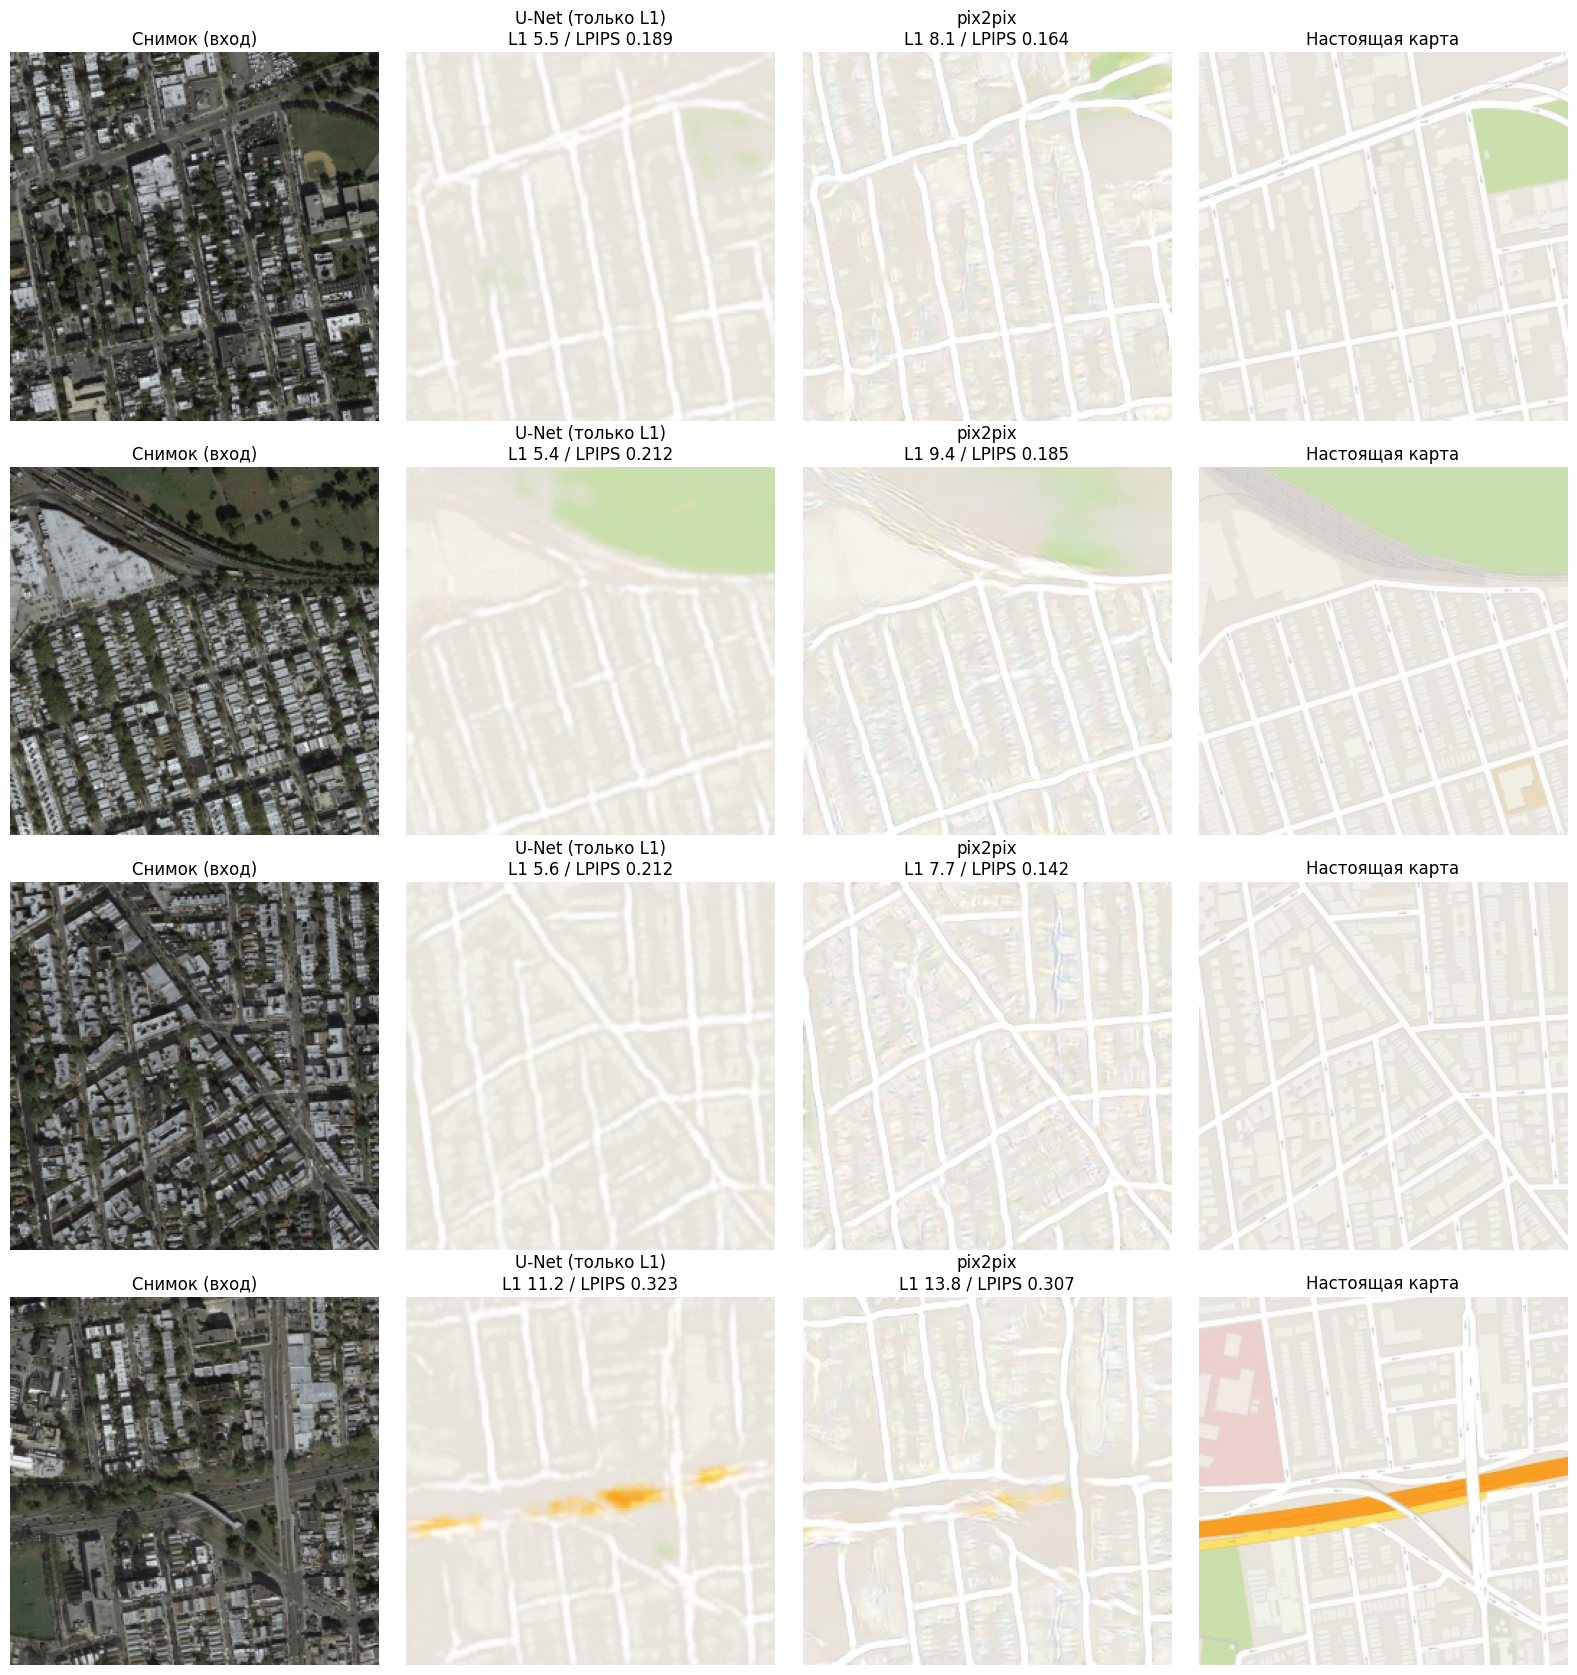

In [10]:
# Номера проверочных пар для показа
SHOW_IDS = [0, 275, 550, 825]

fig, axes = plt.subplots(len(SHOW_IDS), 4, figsize=(16, 4.2 * len(SHOW_IDS)))
for row, idx in zip(axes, SHOW_IDS):
    parts = [("Снимок (вход)", valid_sat[idx])]
    # Метрики в подписи посчитаны для этой пары
    for name in models:
        title = f"{name}\nL1 {results[name]['L1'][idx]:.1f} / LPIPS {results[name]['LPIPS'][idx]:.3f}"
        parts.append((title, predictions[name][idx]))
    parts.append(("Настоящая карта", valid_map[idx]))

    for ax, (title, img) in zip(row, parts):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Графики обучения

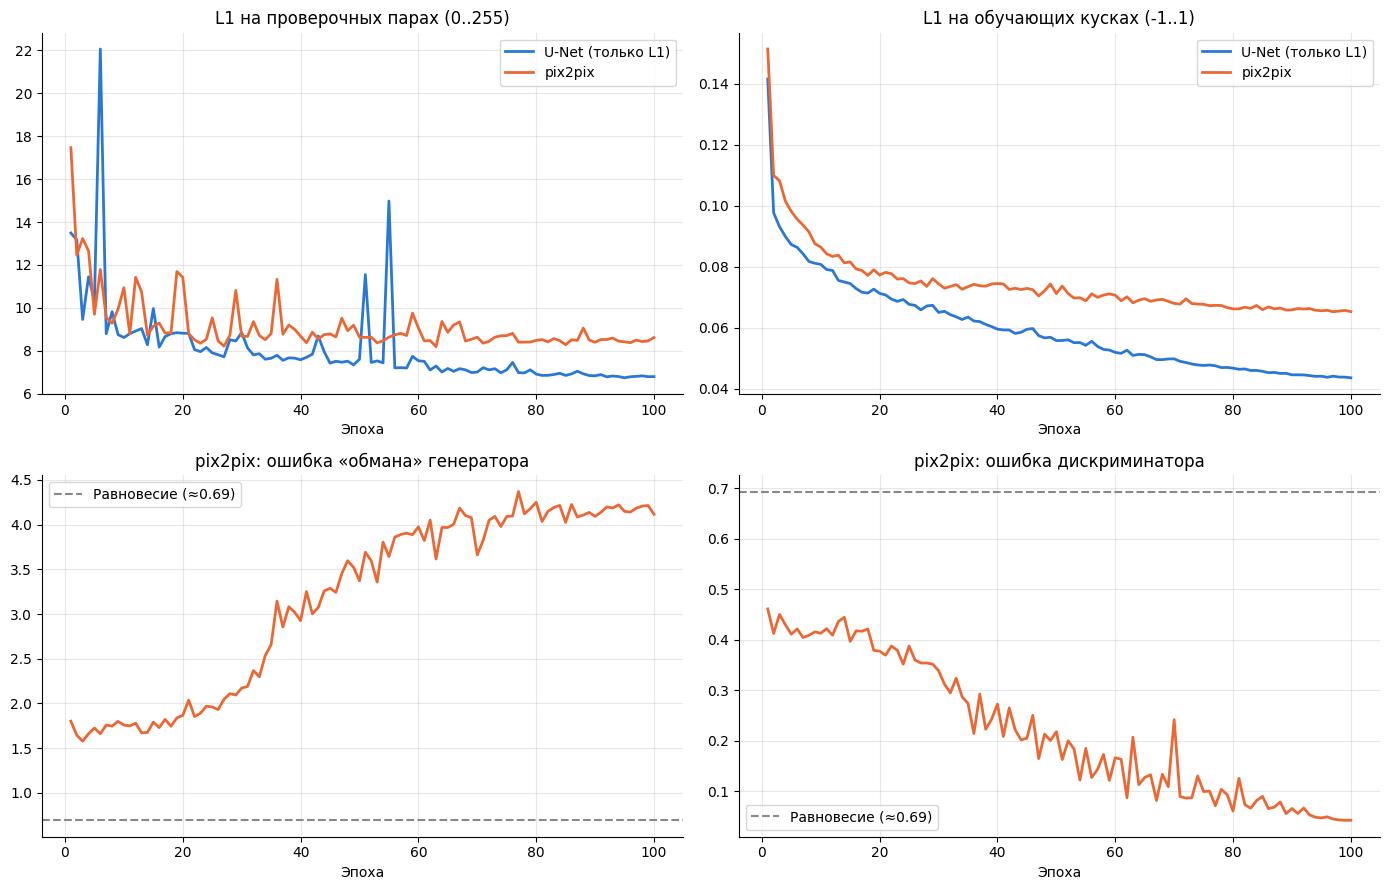

In [11]:
# Цвета линий: синий — U-Net только на L1, оранжевый — pix2pix, серый — уровень равновесия
COLOR_L1, COLOR_GAN, COLOR_BASE = "#2a78d6", "#eb6834", "#8a8984"

epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Ошибка L1 на проверке по ходу обучения обеих моделей
ax = axes[0, 0]
ax.plot(epochs, [h["val_l1"] for h in history_l1], color=COLOR_L1, lw=2, label="U-Net (только L1)")
ax.plot(epochs, [h["val_l1"] for h in history_gan], color=COLOR_GAN, lw=2, label="pix2pix")
ax.set_title("L1 на проверочных парах (0..255)")
ax.set_xlabel("Эпоха")
ax.legend()

# Ошибка L1 на обучающих кусках
ax = axes[0, 1]
ax.plot(epochs, [h["l1"] for h in history_l1], color=COLOR_L1, lw=2, label="U-Net (только L1)")
ax.plot(epochs, [h["l1"] for h in history_gan], color=COLOR_GAN, lw=2, label="pix2pix")
ax.set_title("L1 на обучающих кусках (-1..1)")
ax.set_xlabel("Эпоха")
ax.legend()

# Ошибка «обмана» генератора pix2pix; около 0.69 — дискриминатор не отличает нарисованное от настоящего
ax = axes[1, 0]
ax.plot(epochs, [h["gan"] for h in history_gan], color=COLOR_GAN, lw=2)
ax.axhline(np.log(2), color=COLOR_BASE, lw=1.5, ls="--", label="Равновесие (≈0.69)")
ax.set_title("pix2pix: ошибка «обмана» генератора")
ax.set_xlabel("Эпоха")
ax.legend()

# Ошибка дискриминатора pix2pix
ax = axes[1, 1]
ax.plot(epochs, [h["d"] for h in history_gan], color=COLOR_GAN, lw=2)
ax.axhline(np.log(2), color=COLOR_BASE, lw=1.5, ls="--", label="Равновесие (≈0.69)")
ax.set_title("pix2pix: ошибка дискриминатора")
ax.set_xlabel("Эпоха")
ax.legend()

# Светлая сетка
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 11. Демонстрация на своём снимке

Снимок для демонстрации — файл `image.png` рядом с ноутбуком. Подходит:
- обычный спутниковый снимок — он уменьшается до масштаба датасета (`SCALE`), режется на куски 256×256 с перекрытием, карты кусков склеиваются в одну;
- файл из датасета maps (снимок и карта рядом, ширина вдвое больше высоты) — тогда результат сравнивается с настоящей картой.

Карта, нарисованная pix2pix, сохраняется в папку `results`.

Модель обучена на снимках Google Maps одного масштаба, поэтому лучше всего она работает на похожих снимках городской застройки.

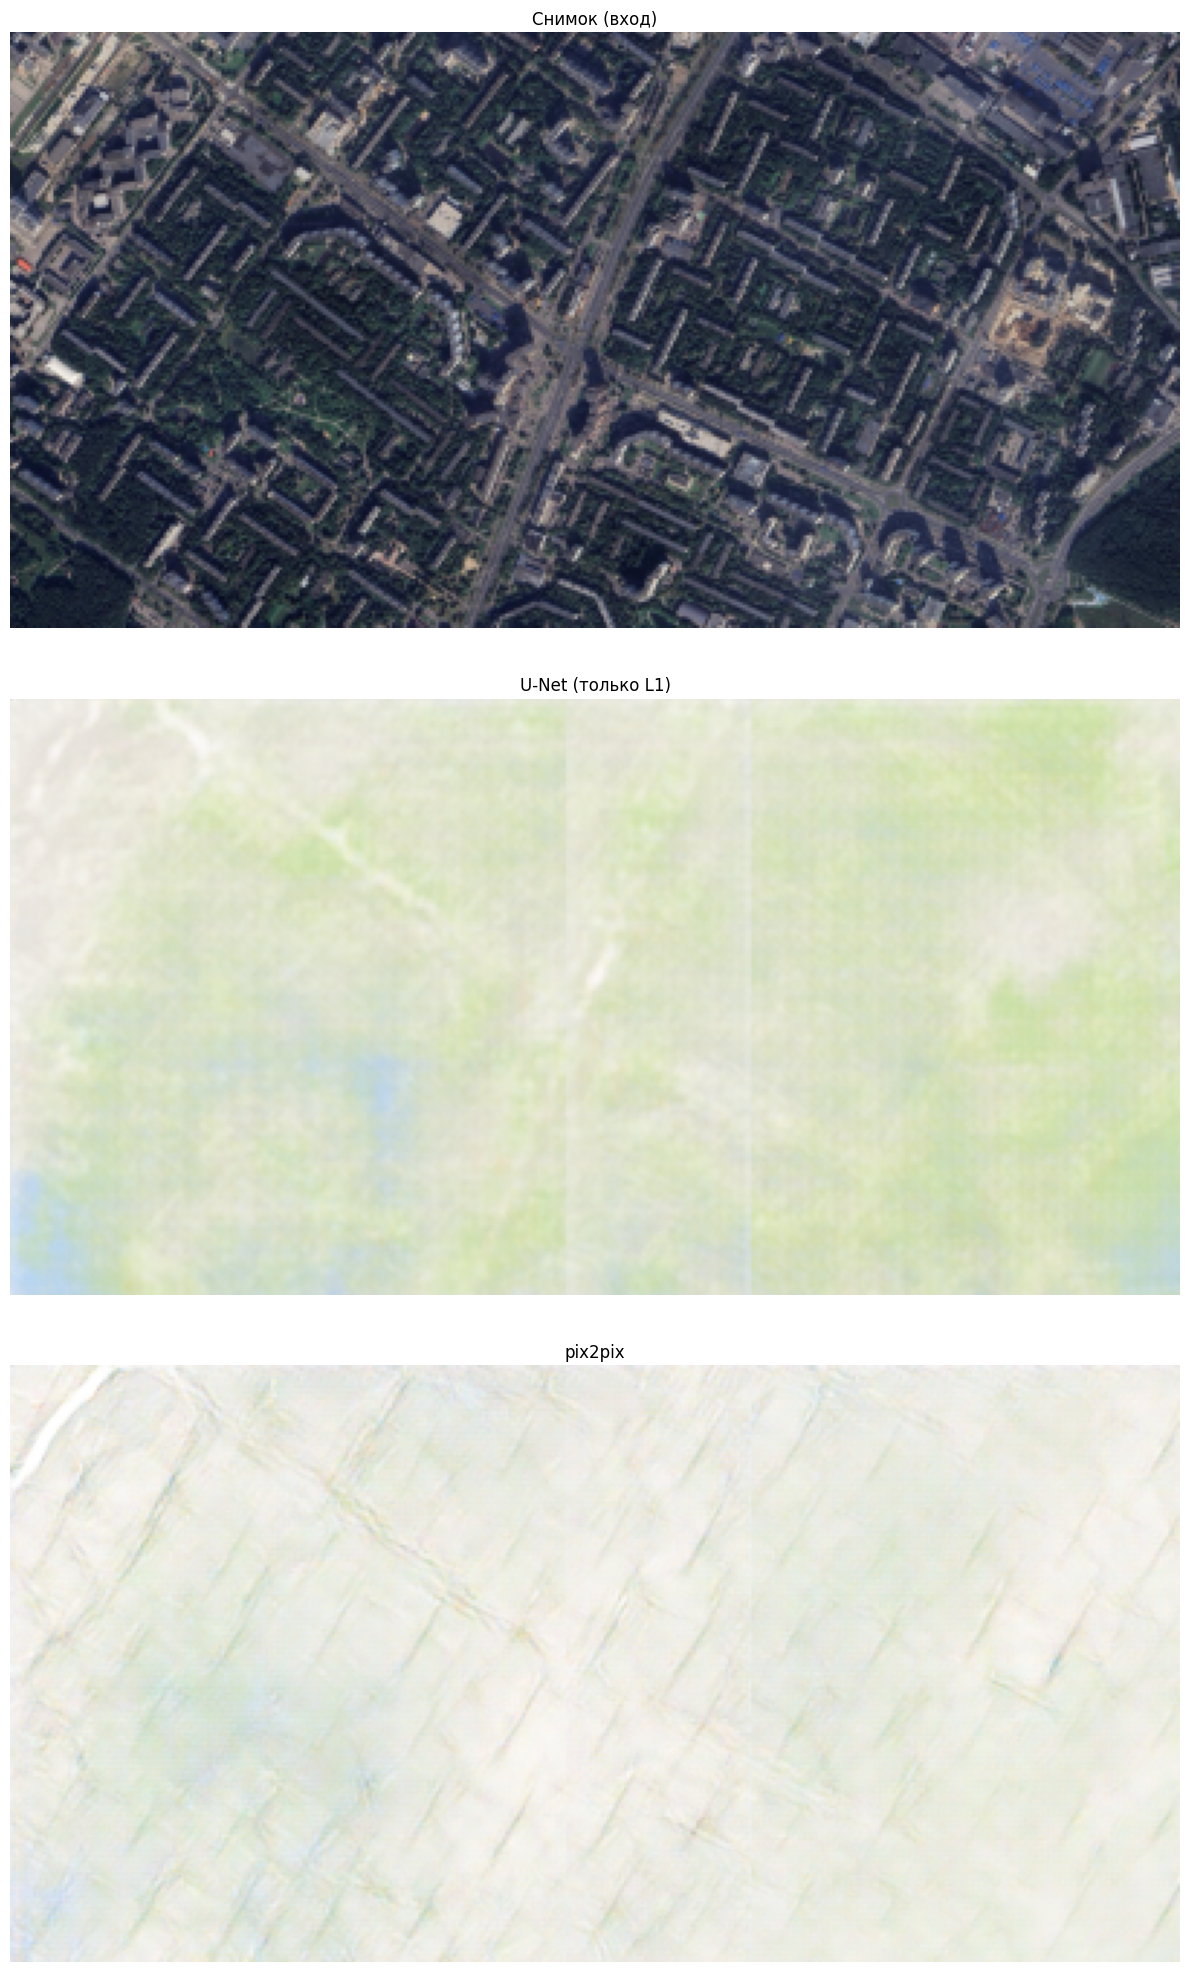

Карта сохранена


In [12]:
# Свой снимок рядом с ноутбуком
DEMO_IMAGE = Path("image.png")
# Уменьшение снимка до масштаба датасета
SCALE = 0.3
# Перекрытие соседних кусков, пикселей
OVERLAP = 64


def translate_large(model, img):
    # Переводит снимок любого размера в карту: режет на куски с перекрытием и склеивает их карты
    h, w = img.shape[:2]
    step = IMG_SIZE - OVERLAP
    # Дополнение краёв отражением, чтобы куски ложились без остатка
    ph = max(IMG_SIZE, int(np.ceil((h - OVERLAP) / step)) * step + OVERLAP)
    pw = max(IMG_SIZE, int(np.ceil((w - OVERLAP) / step)) * step + OVERLAP)
    padded = np.pad(img, ((0, ph - h), (0, pw - w), (0, 0)), mode="reflect")

    corners = [(y, x) for y in range(0, ph - IMG_SIZE + 1, step) for x in range(0, pw - IMG_SIZE + 1, step)]
    tiles = translate(model, [padded[y:y + IMG_SIZE, x:x + IMG_SIZE] for y, x in corners])

    # Склейка: в местах перекрытия карты кусков усредняются
    total = np.zeros((ph, pw, 3))
    count = np.zeros((ph, pw, 1))
    for (y, x), tile in zip(corners, tiles):
        total[y:y + IMG_SIZE, x:x + IMG_SIZE] += tile
        count[y:y + IMG_SIZE, x:x + IMG_SIZE] += 1
    return (total / count)[:h, :w].round().astype(np.uint8)


if not DEMO_IMAGE.exists():
    raise FileNotFoundError(f"Нет файла {DEMO_IMAGE}")
img = read_rgb(DEMO_IMAGE)
h, w = img.shape[:2]

if abs(w - 2 * h) <= 2:
    # Пара из датасета: слева снимок, справа настоящая карта
    sat_img = resize(img[:, :w // 2], IMG_SIZE)
    real_img = resize(img[:, w // 2:], IMG_SIZE)
else:
    # Обычный снимок
    sat_img = cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)
    real_img = None

# Карты обеих моделей
demo_preds = {}
parts = [("Снимок (вход)", sat_img)]
for model_name, model in models.items():
    pred = translate_large(model, sat_img)
    demo_preds[model_name] = pred
    title = model_name
    if real_img is not None:
        title += f"\nL1 {l1_error(pred, real_img):.1f} / LPIPS {lpips_score(pred, real_img):.3f}"
    parts.append((title, pred))
if real_img is not None:
    parts.append(("Настоящая карта", real_img))

# Широкий снимок — картинки друг под другом, иначе в ряд
aspect = sat_img.shape[0] / sat_img.shape[1]
if aspect < 1 / 1.3:
    fig, axes = plt.subplots(len(parts), 1, figsize=(12, (12 * aspect + 0.6) * len(parts)))
else:
    fig, axes = plt.subplots(1, len(parts), figsize=(5 * len(parts), 5 * aspect + 0.6))
for ax, (title, picture) in zip(axes, parts):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Сохранение карты pix2pix
out_path = RESULTS_DIR / f"{DEMO_IMAGE.stem}_map.png"
save_rgb(out_path, demo_preds["pix2pix"])
print("Карта сохранена")

## Выводы

1. **Решена задача** перевода спутникового снимка в схематическую карту на датасете maps (1096 обучающих и 1098 проверочных пар). Обучены две модели с одинаковым генератором U-Net по 100 эпох: только с попиксельной ошибкой L1 и pix2pix (L1 + дискриминатор PatchGAN).

2. **Результаты на проверочных парах:**

   | Модель | L1 ↓ | PSNR, дБ ↑ | SSIM ↑ | LPIPS ↓ |
   |---|---|---|---|---|
   | U-Net (только L1) | **6.79** | **27.28** | **0.749** | 0.256 |
   | pix2pix | 8.76 | 25.59 | 0.630 | **0.199** |

3. **U-Net, обученный только на L1, лучше по попиксельным метрикам** (L1, PSNR, SSIM), но его карты размыты. Сеть рисует «усреднённый» результат: дороги и парки видны, а кварталы залиты ровным фоном, без контуров зданий. Для попиксельных метрик такое усреднение выгодно, поэтому они переоценивают размытую модель.

4. **pix2pix лучше по LPIPS** (0.199 против 0.256), то есть его карты ближе к настоящим с точки зрения восприятия человеком. Дискриминатор не даёт генератору рисовать размыто: дороги получаются чёткими, появляются контуры кварталов и зданий. Расплата — мелкие детали не всегда совпадают с настоящими до пикселя, отсюда более высокая ошибка L1 и меньший SSIM. Это согласуется с выводом авторов pix2pix о том, что попиксельные метрики плохо оценивают качество сгенерированных изображений (сами авторы оценивали карты опросом людей), поэтому здесь они дополнены перцептивной метрикой LPIPS.

5. **По графикам обучения:** ошибка L1 на обучающих кусках у обеих моделей в целом снижается. Ошибка на проверке в первой половине обучения сильно скачет; у U-Net отдельные скачки есть и в начале второй половины (эпохи 51 и 55), после чего, по мере плавного снижения скорости обучения, ошибка выравнивается. У pix2pix к концу обучения дискриминатор заметно сильнее генератора: его ошибка падает до ≈0.04, а ошибка «обмана» генератора растёт до ≈4 (уровень равновесия ≈0.69). Обучение при этом не разрушилось, качество карт на проверке стабильно. Для улучшения можно ослабить дискриминатор, например уменьшить его скорость обучения или добавить шум к его входу.

6. **На собственном снимке результат слабый.** U-Net выдал размытый светлый фон с зелёными и голубыми пятнами, на котором едва угадываются одна-две улицы. pix2pix нарисовал бледную сетку кварталов в правильных направлениях, но ни дороги, ни здания чётко не прорисованы. Также видны швы на стыках кусков, на которые разрезался снимок. Вероятные причины:
   - **Чувствительность к масштабу.** При обучении все снимки были одного масштаба, а случайные вырезки 256 из 286 почти его не меняют. Модель знает, какой ширины дорога и какого размера дом на снимке, и плохо узнаёт их при другом увеличении. Масштаб своего снимка удаётся подобрать только примерно.
   - **Чувствительность к яркости и цвету.** Обучающие снимки сделаны при одних условиях: освещение, сезон, обработка. На своём снимке другая яркость, контраст и длина теней, а густая зелень и тени от домов закрывают дороги.
   - **Небольшой и однородный датасет.** 1096 обучающих пар одного источника и одного масштаба, вероятно, мало, чтобы модель научилась выделять дороги и здания независимо от условий съёмки.

   Улучшить перенос на новые снимки можно расширением обучающих данных: случайным изменением масштаба, яркости, контраста и цвета снимков при обучении, а также добавлением снимков из других источников и условий съёмки.